# The honest loop: a small GPT that tells you the truth about itself

This notebook runs the whole experiment from `guide.md`, top to bottom. The same notebook runs
on a Mac with an Apple GPU (it was executed on an M4, and the outputs you see are from that run)
and on Kaggle with a T4.

What happens, in order, with rough times on an M4:

| step | what | time |
|---|---|---|
| 1 | setup and device check | seconds |
| 2 | download FineWeb-Edu, train a 4,096-token tokenizer, write 25M training tokens | ~1 min |
| 3 | look at what the tokenizer does | seconds |
| 4 | one traced training step: every tensor shape, and the memory bill | ~20 s |
| 5 | check a gradient by hand | ~1 min |
| 6 | 0.1 in six number formats, bit by bit | seconds |
| 7 | break gradient accumulation on purpose | ~8 min |
| 8 | the MFU ladder: one speed trick at a time | ~3 min |
| 9 | the main run, logging loss, grad norm, tokens/s and MFU every step | ~30 min (27 min of timed steps here) |
| 10 | find a step where grad norm moved before the loss | seconds (plus ~2 min if we need the provoked run) |
| 11 | the honest MFU report | seconds |

Every code cell has a markdown cell above it saying what it does, what to expect, and how to
read the output. Read `guide.md` Parts 1 to 10 first if a word here is new to you.

## 1. Setup

This cell finds out where we are running and picks the Python interpreter for the scripts.

- On a Mac, run the notebook from the project folder after `uv sync`, with the project's `.venv`
  as the kernel. `sys.executable` is then the project's Python, so `!{PY} train.py` uses the same
  packages as the notebook.
- On Kaggle, upload the project's `.py` files as a Kaggle dataset named `honest-loop`. The cell
  copies them into `/kaggle/working` and installs `tokenizers` (Kaggle already has torch).

**What to expect:** the torch version, the device (`mps` on a Mac, `cuda` on Kaggle), and the
dtype the matmuls will use (`bfloat16` on the M4, `float16` on a T4, which has no fast bf16).

In [1]:
import json, os, shutil, sys

ON_KAGGLE = os.path.exists("/kaggle/working")
if ON_KAGGLE:
    src = "/kaggle/input/honest-loop"
    for f in os.listdir(src):
        if f.endswith(".py"):
            shutil.copy(os.path.join(src, f), "/kaggle/working")
    os.chdir("/kaggle/working")
    !pip install -q tokenizers
PY = sys.executable

import torch
import flops
dev = flops.device()
print("running on Kaggle" if ON_KAGGLE else "running locally")
print("torch", torch.__version__, "| device", dev, "| matmul dtype", flops.autocast_dtype(dev))

running locally
torch 2.15.0 | device mps | matmul dtype torch.bfloat16


## 2. Build the dataset

`data.py` streams FineWeb-Edu (educational web pages) from the Hugging Face Hub, trains a
byte-level BPE tokenizer with 4,096 tokens on 40M characters of it, and writes:

- `data/fwe/train.bin`: 25,000,000 token ids (2 bytes each, so 50 MB)
- `data/fwe/eval.bin`: 500,000 token ids from documents the tokenizer and the model never train on
- `data/fwe/tokenizer.json` and `data/fwe/meta.json`

**What to expect:** download progress, then the tokenizer training time (a few seconds), then
`meta.json`. The number to look at is `chars_per_token`: about 3.4, meaning one token covers about
3.4 characters of English. The last lines show one sentence cut into tokens. `Ġ` is how the
tokenizer writes a space at the start of a token.

In [2]:
!{PY} data.py --out data/fwe --train-tokens 25M --eval-tokens 500K

  downloaded 5,000 docs, 24M chars, 14s


  downloaded 10,000 docs, 47M chars, 19s


  downloaded 15,000 docs, 70M chars, 27s


  downloaded 20,000 docs, 95M chars, 32s


  downloaded 25,000 docs, 123M chars, 40s


  downloaded 30,000 docs, 147M chars, 45s


downloaded 31,319 docs, 153M chars in 47s


trained a 4,096-token BPE on 40M chars in 2s


{
  "dataset": "HuggingFaceFW/fineweb-edu sample-10BT",
  "vocab_size": 4096,
  "eot_id": 0,
  "dtype": "uint16",
  "tokens": {
    "eval": 500000,
    "train": 25000000
  },
  "docs": {
    "eval": 405,
    "train": 18145
  },
  "chars_per_token": 3.43
}
example: 'The mitochondria is the powerhouse of the cell.'
  -> ['The', 'Ġm', 'it', 'och', 'ond', 'ri', 'a', 'Ġis', 'Ġthe', 'Ġpower', 'h', 'ouse', 'Ġof', 'Ġthe', 'Ġcell', '.']
  -> [451, 287, 274, 3675, 650, 396, 65, 310, 262, 1101, 72, 1188, 278, 262, 1073, 14]


## 3. What the model actually reads

The model never sees letters. It sees token ids. This cell decodes the first 40 ids of the
training file back into text, one token per box, so you can see where the tokenizer cut.

**What to expect:** common words are one token (` the`, ` of`), rarer words are split into
pieces, and id 0 is `<|endoftext|>`, the marker between two documents.

In [3]:
import numpy as np
from tokenizers import Tokenizer
tok = Tokenizer.from_file("data/fwe/tokenizer.json")
ids = np.memmap("data/fwe/train.bin", dtype=np.uint16, mode="r")[:40].tolist()
print("ids:   ", ids)
print("tokens:", " ".join(f"[{tok.decode([i])}]" for i in ids))

ids:    [1775, 541, 605, 442, 359, 672, 645, 262, 1796, 12, 358, 310, 459, 366, 1870, 614, 290, 1121, 400, 741, 979, 840, 578, 709, 1603, 13, 471, 1267, 537, 288, 1345, 343, 476, 888, 1289, 14, 635, 616, 1697, 1117]
tokens: [As] [ one] [ year] [ sh] [if] [ts] [ into] [ the] [ next] [,] [ it] [ is] [ wor] [th] [wh] [ile] [ to] [ look] [ at] [ two] [ art] [ists] [ who] [ use] [ non] [-] [per] [man] [ence] [ and] [ change] [ as] [ their] [ med] [ium] [.] [ It] [ may] [ seem] [ str]


## 4. One traced step: every tensor shape, and what a step costs

`train.py --trace-shapes` runs a normal training step but records every intermediate tensor on
the way: forward activations, the loss, each parameter's gradient, and AdamW's two state tensors
per parameter. It writes them to `runs/shapes/shapes.txt` with one line saying what each
dimension means. We run 2 steps because the memory bill is printed on step 2, once AdamW's
state exists.

**How to read it:** each row is `name  shape  dtype  meaning`. Shapes use the letters
B=64 sequences, T=256 positions, C=384 channels, H=6 heads, D=64 channels per head, V=4,096 tokens.
Notice which tensors are `bfloat16` (the matmul outputs, under autocast) and which stay `float32`
(the residual stream, the weights, the gradients, the optimizer state).

**The memory bill** compares three things: the textbook prediction, autograd's own list of the
tensors it saved for backward, and what the GPU reports. On the M4, autograd saves 6 tensors of
shape (64, 6, 256, 256) in float32 that the textbook does not expect. Guide Part 9 explains why.

**A note on this saved output:** "before forward" reads 283 MB here, not the 148 MB of weights plus
AdamW state. The extra 134 MB is the previous step's logits (64 x 256 x 4,096 bf16), kept alive by a
Python variable. This run found that; `train.py` now deletes the logits after backward, and the
spike and ramp runs in cell 10b, which ran on the fixed code, show 149 MB.

In [4]:
!{PY} train.py --data data/fwe --out runs/shapes --max-steps 2 --trace-shapes --eval-every 0 --sample-tokens 0

model: 12,297,984 params (12.30M), 73.8 MFLOPs per token (6N)
device: mps, matmuls in torch.bfloat16, loss scaling off
peak: Apple M4, 8 GPU cores x 128 ALUs x 2 FLOPs x 1.6 GHz = 3.28 TFLOPS (estimate, same for every dtype)
measured matmul ceiling: 2.81 TFLOPS


2 steps x 16,384 tokens = 0.0M tokens


One training step, B=64, T=256, C=384, H=6, D=64, V=4096, L=6

Dimension letters:
  B  batch      sequences processed side by side in one micro-batch
  T  time       token positions in a sequence
  C  channels   numbers that represent one token (the model width)
  H  heads      independent attention patterns per layer
  D  head dim   channels each head works with, C / H
  V  vocab      possible tokens, one score each at the output

== Forward ==

input_ids                  (64, 256)              int64     token ids: (sequences in the batch, positions)
tok_emb                    (64, 256, 384)         float32   each token id looked up as a C-wide vector
tok_emb + pos_emb          (64, 256, 384)         float32   token vectors plus a learned vector for each position
block0.attn.qkv            (64, 256, 1152)        bfloat16  queries, keys and values for every token, side by side (3C = 3 x 384)
block0.attn.q              (64, 6, 256, 64)       bfloat16  queries split into heads: (batch, h


What one step costs in memory, textbook prediction:
  weights (fp32)                 49.2 MB   12,297,984 params x 4 bytes
  gradients (fp32)               49.2 MB   one gradient per weight, same dtype as the weight
  AdamW state (fp32)             98.4 MB   two running averages per weight (m and v), 4 bytes each
  bf16 weight copies             24.4 MB   autocast casts each matmul weight once per forward and keeps the copy for backward
  activations, blocks          1361.3 MB   6 blocks x tensors saved for backward at B=64, T=256
  activations, loss             268.4 MB   fp32 log-probabilities that cross-entropy keeps for backward
  total                        1850.9 MB
What autograd actually saved for backward: 2522.0 MB
     604.0 MB    6 x (64, 6, 256, 256)    float32
     604.0 MB   12 x (64, 256, 1536)      bfloat16
     327.2 MB   13 x (64, 256, 384)       float32
     302.0 MB   12 x (384, 256, 64)       float32
     268.4 MB    1 x (16384, 4096)        float32
     239.1 MB

saved runs/shapes/ckpt.pt


## 5. Check a gradient by hand

`backward()` claims to know, for every weight, how fast the loss changes when that weight
changes. We test that claim without calculus: nudge one weight up by eps, measure the loss, nudge
it down by eps, measure again, and divide the difference by 2 x eps.

The script checks 5 weights from different layers in three precisions, on the CPU (the M4 GPU
has no fp64).

**What to expect:**
- **fp64:** autograd and the nudge agree to 7 or 8 digits (6.8 at worst). backward() is right.
- **fp32 with eps = 0.001:** they disagree, and one numeric gradient comes out as exactly 0. The
  line under the table says why: near a loss of 8.4, fp32 cannot see a change smaller than about
  1e-6, and some nudges only move the loss by 3.5e-7.
- **bf16:** worse again. bf16 cannot even store the nudge we asked for.
- **The eps sweep:** too large an eps and the formula's approximation is off, too small and the
  difference drowns in rounding. fp64 has a wide good region, fp32 a narrow one, bf16 almost none.

batch: 4 sequences x 64 tokens, model in eval-free train mode (no dropout exists)



== fp64, eps = 1e-05 ==
weight                                   autograd        numeric  rel error digits
tok_emb.weight(1775, 5)              -0.007978404   -0.007978404   2.90e-09    8.5
pos_emb.weight(3, 7)                 -0.006719273   -0.006719273   1.57e-08    7.8
blocks.0.attn.qkv.weight(10, 20)     -0.000176871   -0.000176871   2.93e-08    7.5
blocks.3.mlp.fc.weight(100, 50)      -0.000743333   -0.000743333   6.78e-08    7.2
blocks.5.ln2.weight(17,)              0.000426888    0.000426888   1.70e-07    6.8
  loss 8.4252: fp64 can resolve loss changes of about 1.9e-15; the nudges should move it by 3.5e-09 to 1.6e-07



== fp32, eps = 0.001 ==
weight                                   autograd        numeric  rel error digits
tok_emb.weight(1775, 5)              -0.007978383   -0.008106232   1.58e-02    1.8
pos_emb.weight(3, 7)                 -0.006719274   -0.006675720   6.48e-03    2.2
blocks.0.attn.qkv.weight(10, 20)     -0.000176871    0.000476837   1.37e+00   -0.1
blocks.3.mlp.fc.weight(100, 50)      -0.000743330   -0.000953674   2.21e-01    0.7
blocks.5.ln2.weight(17,)              0.000426891    0.000000000   1.00e+00   -0.0
  loss 8.4252: fp32 can resolve loss changes of about 1.0e-06; the nudges should move it by 3.5e-07 to 1.6e-05



== bf16, eps = 0.1 ==
weight                                   autograd        numeric  rel error digits
tok_emb.weight(1775, 5)              -0.007995605   -0.006690025   1.63e-01    0.8
pos_emb.weight(3, 7)                 -0.006896973   -0.007200241   4.21e-02    1.4
blocks.0.attn.qkv.weight(10, 20)     -0.000176430   -0.001535416   8.85e-01    0.1
blocks.3.mlp.fc.weight(100, 50)      -0.000743866   -0.002179146   6.59e-01    0.2
blocks.5.ln2.weight(17,)              0.000427246    0.000114441   7.32e-01    0.1
  loss 8.4243: bf16 can resolve loss changes of about 6.6e-02; the nudges should move it by 3.5e-05 to 1.6e-03
bf16 stores the weight with only 8 significant bits, so the nudge it actually applied was:
  tok_emb.weight(1775, 5): asked for 0.1, stored 0.100098
  pos_emb.weight(3, 7): asked for 0.1, stored 0.100098
  blocks.0.attn.qkv.weight(10, 20): asked for 0.1, stored 0.100098
  blocks.3.mlp.fc.weight(100, 50): asked for 0.1, stored 0.100098
  blocks.5.ln2.weight(17,): aske

   1e+00    3.1e-01    3.1e-01    1.8e-01
   3e-01    9.3e-02    9.4e-02    1.5e-01
   1e-01    1.1e-02    7.1e-03    6.6e-01
   3e-02    1.2e-03    4.7e-02    1.3e+00
   1e-02    1.2e-04    3.8e-02    1.1e+00
   3e-03    1.2e-05    1.4e-02    1.5e+00
   1e-03    1.2e-06    2.2e-01    1.0e+00
   3e-04    1.2e-07    5.1e-01    9.8e-01
   1e-04    3.8e-09    8.4e-01    1.0e+00
   3e-05    2.6e-09    9.5e-01    1.0e+00
   1e-05    6.8e-08    1.0e+00    1.0e+00
   3e-06    3.5e-08    1.0e+00    1.0e+00
   1e-06    3.1e-07    1.0e+00    1.0e+00
   3e-07    7.9e-07    1.0e+00    1.0e+00
   1e-07    2.1e-06    1.0e+00    1.0e+00
   3e-08    1.2e-05    1.0e+00    1.0e+00
   1e-08    2.2e-05    1.0e+00    1.0e+00
   3e-09    1.6e-04    1.0e+00    1.0e+00
   1e-09    2.5e-03    1.0e+00    1.0e+00
   3e-10    2.5e-03    1.0e+00    1.0e+00
   1e-10    3.7e-03    1.0e+00    1.0e+00

wrote runs/gradcheck.json


wrote plots to plots/


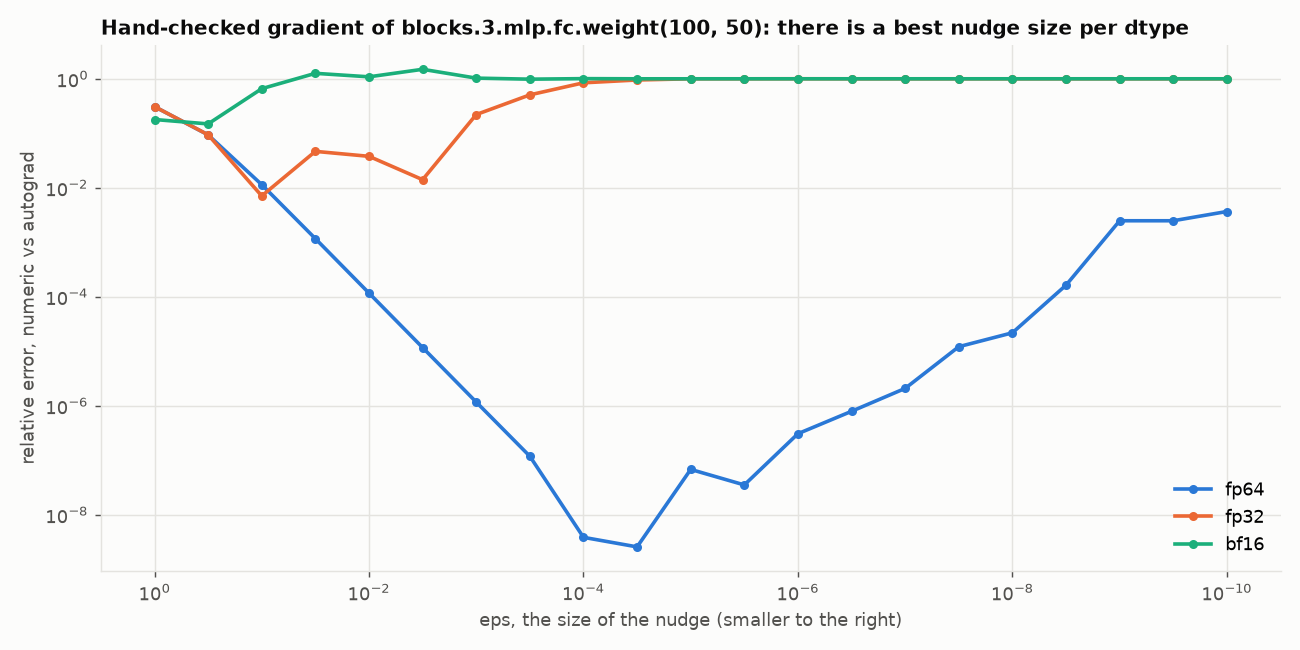

In [5]:
!{PY} gradcheck.py --data data/fwe
!{PY} plot.py --gradcheck runs/gradcheck.json --out plots
from IPython.display import Image, display
display(Image("plots/gradcheck.png"))

## 6. The number 0.1 in six formats

`fp_bits.py` writes 0.1 out by hand in fp32, fp16, bf16, fp8 E4M3, fp8 E5M2 and fp4 E2M1: first
in binary, then as 1.something x 2^e, then rounded to each format's mantissa width. It then asks
PyTorch to do the same conversion and checks every bit.

**How to read it:** each format prints `sign | exponent | mantissa` and the value actually stored.
`MATCH` means PyTorch produced the same bits as the hand method. Watch the error grow as the
mantissa shrinks: fp32 is off by 0.0000015%, bf16 by 0.1%, E5M2 by 6%, and fp4 cannot store 0.1
at all (it rounds to 0). The last four lines show why bf16 is the safer 16-bit format for training.

In [6]:
!{PY} fp_bits.py

Range and precision of each format:
  fp32      max 3.403e+38   smallest normal 1.18e-38   smallest subnormal 1.4e-45    ~7.2 decimal digits
  fp16      max 6.55e+04    smallest normal 6.1e-05    smallest subnormal 5.96e-08   ~3.3 decimal digits
  bf16      max 3.39e+38    smallest normal 1.18e-38   smallest subnormal 9.18e-41   ~2.4 decimal digits
  fp8 E4M3  max 448         smallest normal 0.0156     smallest subnormal 0.00195    ~1.2 decimal digits
  fp8 E5M2  max 5.734e+04   smallest normal 6.1e-05    smallest subnormal 1.53e-05   ~0.9 decimal digits
  fp4 E2M1  max 6           smallest normal 1          smallest subnormal 0.5        ~0.6 decimal digits

0.1 in binary is 0.0001100110011001100110011001100110011001... (it never ends for 0.1)

== fp32 ==
  write it as 1.something x 2^e: 0.1 = 1.6 x 2^-4
  mantissa = the part after '1.' in binary: 0.6 -> 0.1001100110011001100110011001100...
  stored exponent = -4 + bias 127 = 123
  keep 23 mantissa bits: 10011001100110011001100 | dropp

## 7. Break gradient accumulation on purpose

Each optimizer step here is built from 4 micro-batches with sequences of length 8, 32, 128 and
256. `accum.py` trains the same model twice from the same starting weights on the same data:

- **correct:** sum every token's loss across the 4 micro-batches, divide by the total token count
- **broken:** average each micro-batch's loss, then average the 4 averages

The table printed first is the whole story in numbers: under the broken method, a token in the
8-token micro-batch counts 13.25x more than it should, and a token in the 256-token micro-batch
counts 0.41x.

**What to expect:** two training logs of 300 steps each (the correct run is slower because it
also computes the broken gradient at the same weights, to measure the difference), then a
summary. The plot below has three panels: the loss each method *reports*, the held-out loss of
each model, and how far apart the two gradients are at every step.

4 micro-batches of 16 sequences, lengths [8, 32, 128, 256]: 6,784 tokens per step
weight each single token gets in the step's loss:
  length  tokens    correct     broken  broken / correct
       8     128   1.47e-04   1.95e-03            13.25x
      32     512   1.47e-04   4.88e-04             3.31x
     128    2048   1.47e-04   1.22e-04             0.83x
     256    4096   1.47e-04   6.10e-05             0.41x


[correct] step 1/300 reported 8.3933 true 8.3933 eval 8.2270 grad error 0.669 cosine 0.8356 (2s)


[correct] step 25/300 reported 6.8872 true 6.8872 eval 6.8944 grad error 1.194 cosine 0.7489 (21s)


[correct] step 50/300 reported 6.5289 true 6.5289 eval 6.5023 grad error 1.742 cosine 0.5261 (40s)


[correct] step 75/300 reported 6.1937 true 6.1937 eval 6.2298 grad error 1.483 cosine 0.5911 (60s)


[correct] step 100/300 reported 6.0781 true 6.0781 eval 6.0708 grad error 1.693 cosine 0.5519 (80s)


... (19 outputs left out)

[broken] step 275/300 reported 6.0880 true 6.0442 eval 6.0587 (167s)


[broken] step 300/300 reported 6.0624 true 6.0774 eval 6.0409 (183s)



final held-out loss: correct 5.5952, broken 6.0409, gap +0.4457
broken vs correct gradient, relative error: median 1.838, min 0.465, max 3.476
broken run's last step: it reports 6.0624, the true token-weighted loss is 6.0774


wrote plots to plots/


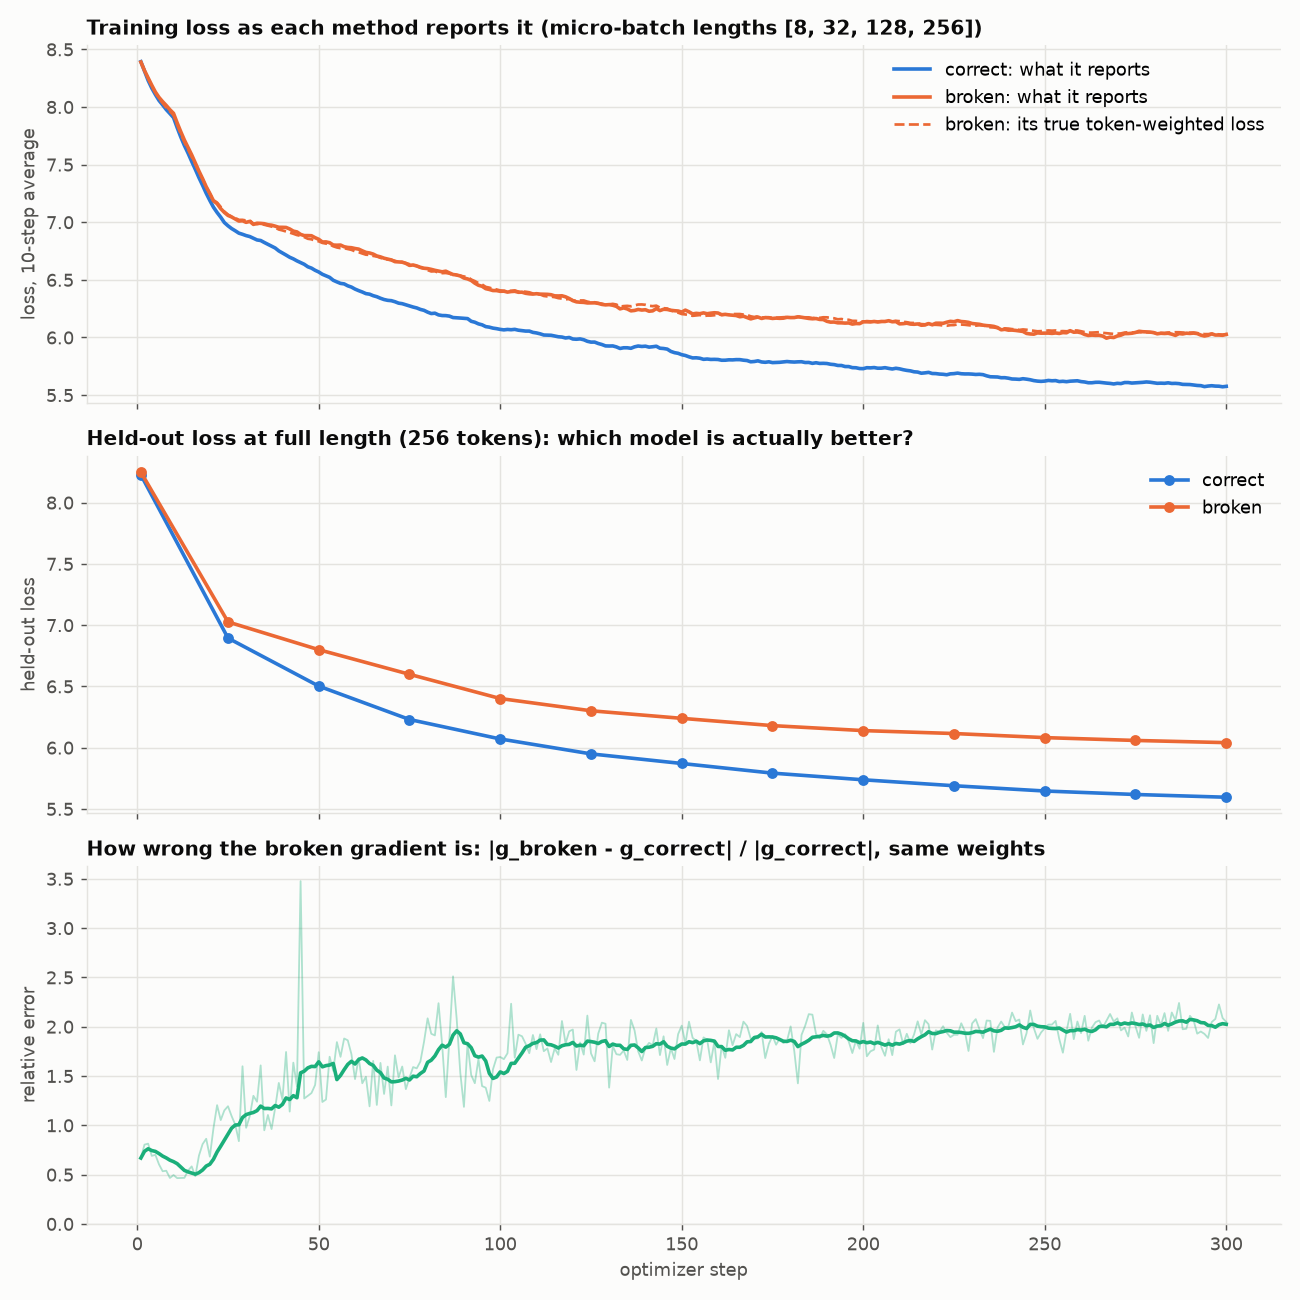

In [7]:
!{PY} accum.py --data data/fwe --out runs/accum
!{PY} plot.py --accum runs/accum --out plots
display(Image("plots/accum.png"))

## 8. The MFU ladder

`ladder.py` starts from the slowest reasonable setup and adds one change per rung: PyTorch's
attention kernel, bf16 autocast, a 4x bigger batch, fused AdamW, and torch.compile. Each rung
trains 10 steps and prints all of them. Steps 1 to 3 pay one-off costs, so the rung's tokens/s and
MFU come from steps 4 to 10.

**How to read it:** MFU = 6 x N x tokens per second / peak FLOPS, with N = 12.3M parameters and
peak = 3.28 TFLOPS (our estimate for the M4's GPU; Apple publishes no number). A rung that fails
on this machine is reported as failed, not hidden. The last block times forward, backward and
the optimizer separately for the fastest rung, which shows where a step's time goes.

**What to expect on an M4:** PyTorch's attention kernel buys nothing here, because on Apple GPUs it
falls back to the same plain math (Part 9 shows the evidence in memory). torch.compile is the one
big jump (+20% in this run, +34% in an earlier test), because it fuses the many small elementwise
operations (LayerNorm, GELU, residual adds, the loss) into fewer kernels, so the GPU spends less
time reading and writing memory between them.

**The absolute numbers depend on how hot the chip is.** This saved run came after 10 minutes of
gradcheck and accumulation work, on a fanless MacBook Air, and every rung ran about 40% slower than
in an earlier test on a cool chip (baseline 11,112 against 17,524 tok/s; compile 15,347 against
25,378). The matmul ceiling tells the same story: 2.81 TFLOPS in cell 4, 1.53 when the main run
started. Compare rungs with each other, not with another run.


== baseline: attn=manual dtype=fp32 batch=16 fused_adam=False compile=False ==


  step  1      393 ms    10,419 tok/s  mfu  23.5%  loss 8.405   (warm-up, not counted)
  step  2      256 ms    16,020 tok/s  mfu  36.1%  loss 8.092   (warm-up, not counted)
  step  3      282 ms    14,515 tok/s  mfu  32.7%  loss 7.916   (warm-up, not counted)
  step  4      322 ms    12,715 tok/s  mfu  28.6%  loss 7.875
  step  5      386 ms    10,619 tok/s  mfu  23.9%  loss 7.774
  step  6      399 ms    10,271 tok/s  mfu  23.1%  loss 7.696
  step  7      397 ms    10,320 tok/s  mfu  23.2%  loss 7.564
  step  8      369 ms    11,096 tok/s  mfu  25.0%  loss 7.389
  step  9      355 ms    11,535 tok/s  mfu  26.0%  loss 7.318
  step 10      353 ms    11,618 tok/s  mfu  26.2%  loss 7.171
  -> steps 4-10: 11,112 tok/s, MFU 25.0%

== + sdpa: attn=sdpa dtype=fp32 batch=16 fused_adam=False compile=False ==


  step  1      356 ms    11,496 tok/s  mfu  25.9%  loss 8.405   (warm-up, not counted)
  step  2      580 ms     7,058 tok/s  mfu  15.9%  loss 8.092   (warm-up, not counted)
  step  3      728 ms     5,629 tok/s  mfu  12.7%  loss 7.916   (warm-up, not counted)
  step  4      485 ms     8,444 tok/s  mfu  19.0%  loss 7.875
  step  5      431 ms     9,507 tok/s  mfu  21.4%  loss 7.774
  step  6      404 ms    10,142 tok/s  mfu  22.8%  loss 7.696
  step  7      382 ms    10,720 tok/s  mfu  24.1%  loss 7.564
  step  8      369 ms    11,088 tok/s  mfu  25.0%  loss 7.389
  step  9      370 ms    11,070 tok/s  mfu  24.9%  loss 7.318
  step 10      359 ms    11,421 tok/s  mfu  25.7%  loss 7.171
  -> steps 4-10: 10,240 tok/s, MFU 23.1%



== + bf16 autocast: attn=sdpa dtype=bf16 batch=16 fused_adam=False compile=False ==


  step  1      308 ms    13,292 tok/s  mfu  29.9%  loss 8.405   (warm-up, not counted)
  step  2      288 ms    14,219 tok/s  mfu  32.0%  loss 8.092   (warm-up, not counted)
  step  3      307 ms    13,323 tok/s  mfu  30.0%  loss 7.916   (warm-up, not counted)
  step  4      323 ms    12,697 tok/s  mfu  28.6%  loss 7.875
  step  5      336 ms    12,202 tok/s  mfu  27.5%  loss 7.774
  step  6      341 ms    12,014 tok/s  mfu  27.1%  loss 7.696
  step  7      344 ms    11,905 tok/s  mfu  26.8%  loss 7.564
  step  8      339 ms    12,083 tok/s  mfu  27.2%  loss 7.389
  step  9      341 ms    12,013 tok/s  mfu  27.1%  loss 7.318
  step 10      341 ms    12,002 tok/s  mfu  27.0%  loss 7.171
  -> steps 4-10: 12,126 tok/s, MFU 27.3%

== + batch 64: attn=sdpa dtype=bf16 batch=64 fused_adam=False compile=False ==


  step  1     1378 ms    11,887 tok/s  mfu  26.8%  loss 8.400   (warm-up, not counted)
  step  2     1417 ms    11,562 tok/s  mfu  26.0%  loss 8.104   (warm-up, not counted)
  step  3     1284 ms    12,756 tok/s  mfu  28.7%  loss 7.926   (warm-up, not counted)
  step  4     1280 ms    12,796 tok/s  mfu  28.8%  loss 7.834
  step  5     1281 ms    12,791 tok/s  mfu  28.8%  loss 7.727
  step  6     1284 ms    12,760 tok/s  mfu  28.7%  loss 7.606
  step  7     1291 ms    12,686 tok/s  mfu  28.6%  loss 7.476
  step  8     1282 ms    12,778 tok/s  mfu  28.8%  loss 7.328
  step  9     1280 ms    12,798 tok/s  mfu  28.8%  loss 7.200
  step 10     1335 ms    12,275 tok/s  mfu  27.6%  loss 7.077
  -> steps 4-10: 12,695 tok/s, MFU 28.6%


... (3 outputs left out)

  step  1     1699 ms     9,642 tok/s  mfu  21.7%  loss 8.400   (warm-up, not counted)
  step  2     1013 ms    16,176 tok/s  mfu  36.4%  loss 8.104   (warm-up, not counted)
  step  3     1052 ms    15,580 tok/s  mfu  35.1%  loss 7.926   (warm-up, not counted)
  step  4     1112 ms    14,734 tok/s  mfu  33.2%  loss 7.834
  step  5     1054 ms    15,547 tok/s  mfu  35.0%  loss 7.727
  step  6     1047 ms    15,646 tok/s  mfu  35.2%  loss 7.606
  step  7     1103 ms    14,850 tok/s  mfu  33.4%  loss 7.476
  step  8     1049 ms    15,613 tok/s  mfu  35.2%  loss 7.328
  step  9     1045 ms    15,674 tok/s  mfu  35.3%  loss 7.200
  step 10     1062 ms    15,430 tok/s  mfu  34.7%  loss 7.077
  -> steps 4-10: 15,347 tok/s, MFU 34.6%



== where the time goes, + torch.compile (5 steps after 3 warm-up steps, synced between phases) ==


  forward      374.9 ms   35.7%
  backward     664.5 ms   63.2%
  optimizer     12.0 ms    1.1%
  total       1051.4 ms

summary
  rung                   tok/s     MFU
  baseline              11,112   25.0%
  + sdpa                10,240   23.1%
  + bf16 autocast       12,126   27.3%
  + batch 64            12,695   28.6%
  + fused AdamW         12,751   28.7%
  + torch.compile       15,347   34.6%
wrote runs/ladder.json


wrote plots to plots/


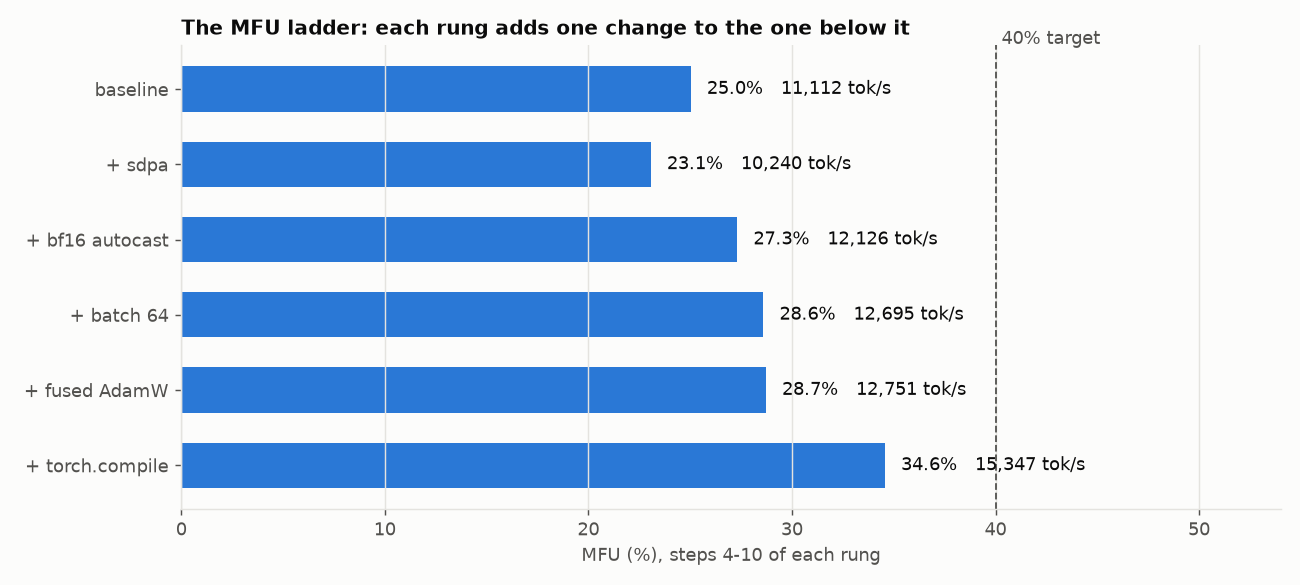

In [8]:
!{PY} ladder.py --data data/fwe
!{PY} plot.py --ladder runs/ladder.json --out plots
display(Image("plots/ladder.png"))

## 9. The main run

1,519 steps of 16,384 tokens each (64 sequences x 256 tokens): one pass over the 25M training
tokens (24.9M; the last partial batch is dropped). The settings are the ladder's top rung (bf16 autocast, fused AdamW, torch.compile), with
AdamW at learning rate 1e-3, 50 warmup steps, a cosine decay, and grad clip 1.0. Every step writes one line to `runs/main/metrics.jsonl` with the four traces:

| trace | what it catches |
|---|---|
| loss | whether the model is learning at all |
| grad norm | trouble, before the loss shows it |
| tokens per second | whether something quietly got slower |
| MFU | whether the machine is being wasted |

**What to expect:** the first lines list the parameter count (12,297,984), the peak and where it
came from, and the measured matmul ceiling. Then `compile check`: before training, the script
compares torch.compile's gradients with plain PyTorch's on one batch and refuses to train if any
parameter differs by more than 1%. That check exists because of a real bug we hit (guide
Part 15): on Apple GPUs, compile once returned a position-embedding gradient 64x too large.
Then the memory bill, a line every 10 steps, a
held-out loss every 100 steps, and at the end a 200-token sample. Held-out loss starts near
ln(4096) = 8.32 (random guessing) and ended at 3.92 in our run. In this saved output, the memory
bill's "before forward" line includes the stale logits described in cell 4.

In [9]:
!{PY} train.py --data data/fwe --out runs/main --compile --fused-adam

model: 12,297,984 params (12.30M), 73.8 MFLOPs per token (6N)
device: mps, matmuls in torch.bfloat16, loss scaling off
peak: Apple M4, 8 GPU cores x 128 ALUs x 2 FLOPs x 1.6 GHz = 3.28 TFLOPS (estimate, same for every dtype)
measured matmul ceiling: 1.53 TFLOPS
1519 steps x 16,384 tokens = 24.9M tokens


compile check: largest gradient difference vs eager is 0.011% (blocks.2.ln2.bias)


eval step 0: held-out loss 8.3963 (random guessing would be ln(4096) = 8.3178)


step 1/1519 loss 8.4000 grad_norm 4.455 lr 2.00e-05 14,453 tok/s mfu 32.5% (1134 ms)



What one step costs in memory, textbook prediction:
  weights (fp32)                 49.2 MB   12,297,984 params x 4 bytes
  gradients (fp32)               49.2 MB   one gradient per weight, same dtype as the weight
  AdamW state (fp32)             98.4 MB   two running averages per weight (m and v), 4 bytes each
  bf16 weight copies             24.4 MB   autocast casts each matmul weight once per forward and keeps the copy for backward
  activations, blocks          1361.3 MB   6 blocks x tensors saved for backward at B=64, T=256
  activations, loss             268.4 MB   fp32 log-probabilities that cross-entropy keeps for backward
  total                        1850.9 MB
What autograd actually saved for backward: 2295.6 MB
     503.3 MB    5 x (64, 6, 256, 256)    float32
     327.2 MB   13 x (64, 256, 384)       float32
     302.0 MB    6 x (16384, 1536)        bfloat16
     302.0 MB    6 x (64, 256, 1536)      bfloat16
     268.4 MB    1 x (16384, 4096)        float32
     239.1 M

step 3/1519 loss 8.1337 grad_norm 2.694 lr 6.00e-05 15,624 tok/s mfu 35.2% (1029 ms)


... (174 outputs left out)

step 1519/1519 loss 3.9018 grad_norm 0.650 lr 1.00e-04 15,230 tok/s mfu 34.3% (1065 ms)


eval step 1519: held-out loss 3.9246


saved runs/main/ckpt.pt



sample:
The most important thing about learning is a few kind of information related to your students's development and caregivers is an example of your research.
Last month, the project, and the Self-Based Active Climate change helps your child with learning.
Discussion is easy to follow to this list.
The project provides a strong study that is to provide the importance of learning to readiness and the work of teaching.
This project provides the development of learning how to understand more awareness and how to learn from the research project.
What to learn what to teach is learning?
Here is a class of learning?
One of the most important ways to work with a classes of learning is to teach students, and students learn more about the classroom and their learning experience.
The school teacher is to learn and learning that teachers will learn how students will not only learn.
The classroom is that when the students are learning a classroom, and it can


## 9b. The four traces

Four panels, one per trace, sharing the step axis. Pale lines are raw per-step values; the solid
line is a 20-step average. The orange dots on the loss panel are held-out losses. The MFU panel has
the 40% target dashed and the big-matmul ceiling dotted: the fraction of our estimated peak that a
single huge matmul reaches, which is about as good as any real kernel gets on this chip.

wrote plots to plots/


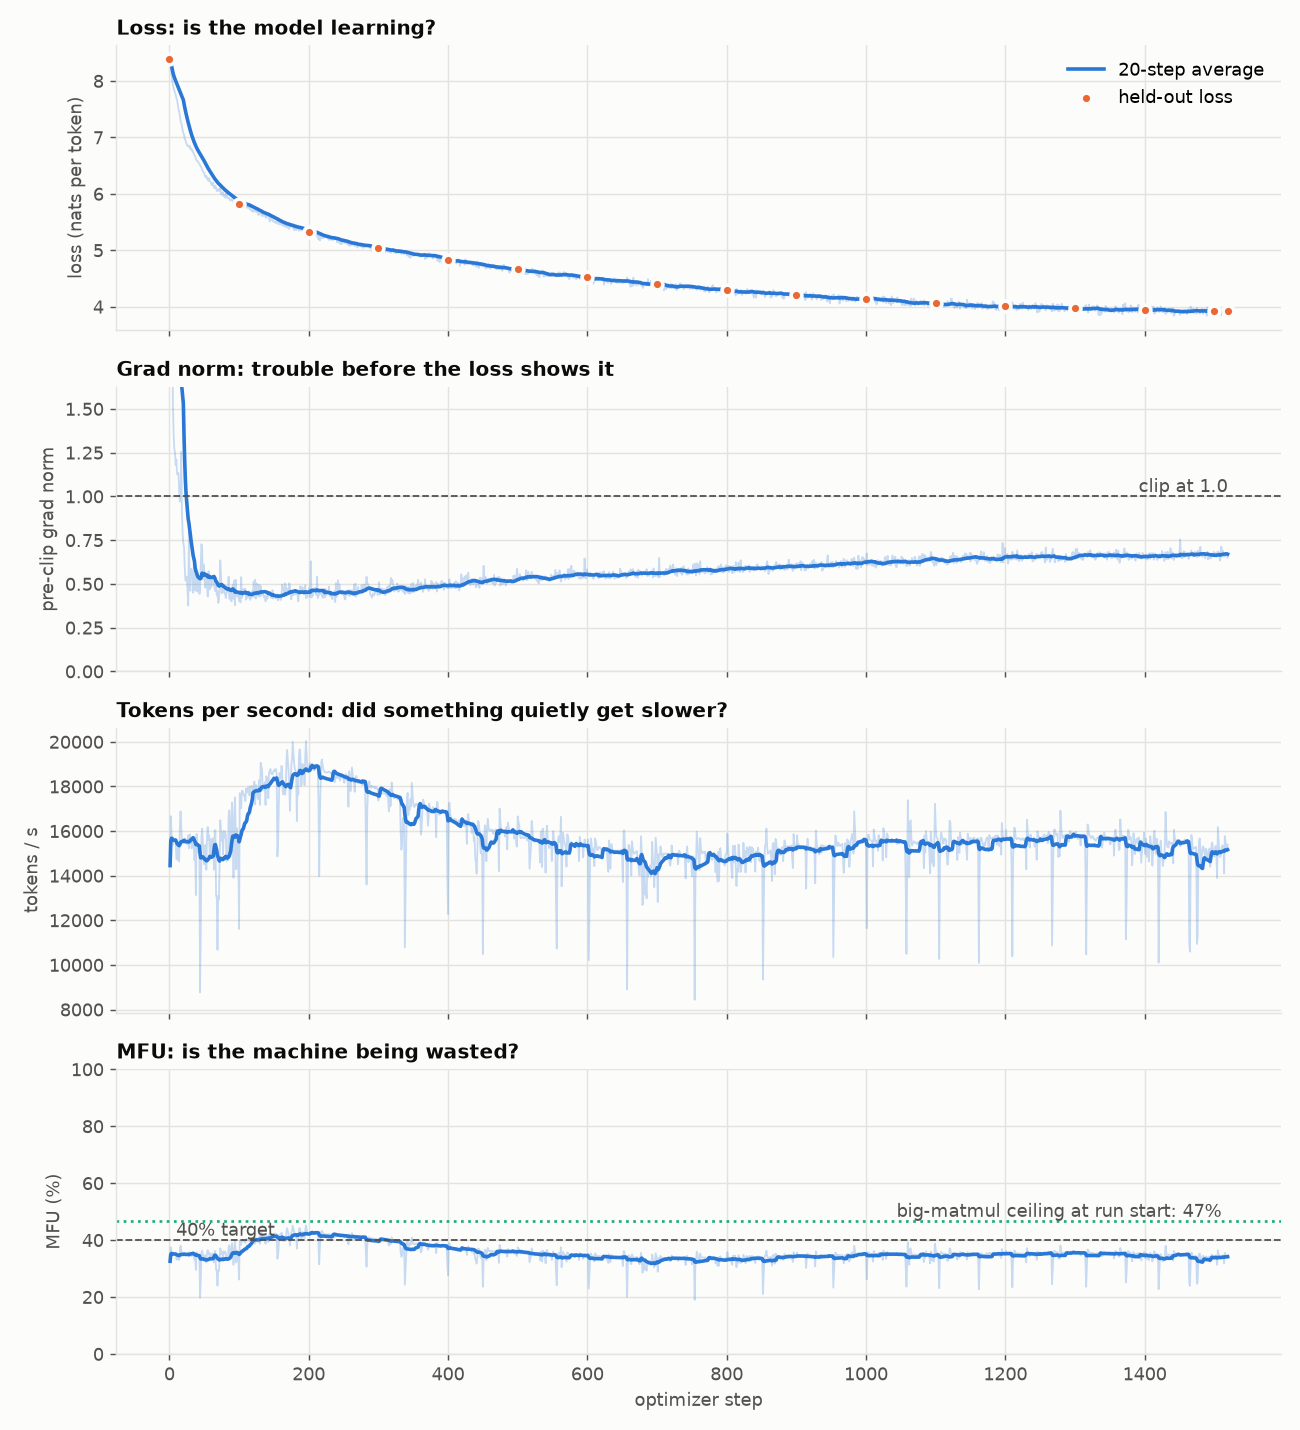

In [10]:
!{PY} plot.py --main runs/main --out plots
display(Image("plots/trace.png"))

## 10. Find a step where the grad norm moved before the loss

`find_lead.py` scores every step against the 20 steps before it (a robust z-score) and looks for a
grad-norm jump (z > 4) followed within 15 steps by a loss jump (z > 4), with the loss quiet just
before. Warmup (the first 100 steps) is skipped because everything moves at once there.

**What to expect:** either a list of events with the clearest one printed step by step, or "no
step where the grad norm moved first". A calm run often has none.

In [11]:
!{PY} find_lead.py runs/main
LEAD_RUN = "runs/main" if json.load(open("runs/main/lead.json"))["best"] else None
print("natural event found" if LEAD_RUN else "no natural event: the next cell provokes one")

1519 steps; looking for grad-norm z > 4.0 followed within 15 steps by loss z > 4.0 (baseline: previous 20 steps, first 100 steps skipped)
no step where the grad norm moved first. Try the provoked run (train.py --lr-spike).
wrote runs/main/lead.json


no natural event: the next cell provokes one


## 10b. Provoke an event, two ways

Two short side runs of the same model, with a deliberate disturbance at step 100. These are
provoked events, and the guide labels them as such.

1. **Spike:** learning rate x10 for 5 steps. Expect the grad norm and the loss to jump in the
   *same* step, so `find_lead.py` reports no lead: a sudden shock hits both at once.
2. **Ramp:** learning rate climbing from 1x to 20x over 60 steps. Now instability builds up
   gradually. The grad norm starts climbing first, while the loss still looks normal, and the
   loss follows several steps later. This is the pattern that makes grad norm an early warning.

The plot shows the main run's natural event if it had one, otherwise the ramp.

model: 12,297,984 params (12.30M), 73.8 MFLOPs per token (6N)
device: mps, matmuls in torch.bfloat16, loss scaling off
peak: Apple M4, 8 GPU cores x 128 ALUs x 2 FLOPs x 1.6 GHz = 3.28 TFLOPS (estimate, same for every dtype)
measured matmul ceiling: 1.71 TFLOPS


150 steps x 16,384 tokens = 2.5M tokens


compile check: largest gradient difference vs eager is 0.011% (blocks.2.ln2.bias)


step 1/150 loss 8.4000 grad_norm 4.455 lr 2.00e-05 14,592 tok/s mfu 32.9% (1123 ms)



What one step costs in memory, textbook prediction:
  weights (fp32)                 49.2 MB   12,297,984 params x 4 bytes
  gradients (fp32)               49.2 MB   one gradient per weight, same dtype as the weight
  AdamW state (fp32)             98.4 MB   two running averages per weight (m and v), 4 bytes each
  bf16 weight copies             24.4 MB   autocast casts each matmul weight once per forward and keeps the copy for backward
  activations, blocks          1361.3 MB   6 blocks x tensors saved for backward at B=64, T=256
  activations, loss             268.4 MB   fp32 log-probabilities that cross-entropy keeps for backward
  total                        1850.9 MB
What autograd actually saved for backward: 2295.6 MB
     503.3 MB    5 x (64, 6, 256, 256)    float32
     327.2 MB   13 x (64, 256, 384)       float32
     302.0 MB    6 x (16384, 1536)        bfloat16
     302.0 MB    6 x (64, 256, 1536)      bfloat16
     268.4 MB    1 x (16384, 4096)        float32
     239.1 M

step 3/150 loss 8.1337 grad_norm 2.694 lr 6.00e-05 14,152 tok/s mfu 31.9% (1170 ms)


... (35 outputs left out)

saved runs/ramp/ckpt.pt


200 steps; looking for grad-norm z > 4.0 followed within 15 steps by loss z > 4.0 (baseline: previous 20 steps, first 60 steps skipped)
  grad norm jumped at step 103 (0.437 -> 0.583, z=5.3); loss followed at step 110 (5.8646 -> 6.0373, z=4.8); lead 7 steps

steps around the clearest event (grad norm at 103, loss at 110):
   step     loss  loss z  grad norm  grad z
     98   5.8266    -1.7      0.418    -0.8
     99   5.8573    -0.8      0.435     0.2
    100   5.8344    -1.0      0.388    -1.4
    101   5.8126    -1.2      0.451     0.8
    102   5.8641    -0.1      0.406    -1.1
    103   5.8779     0.3      0.583     5.3 <- grad norm moves
    104   5.8135    -1.2      0.549     4.0
    105   5.8237    -1.0      0.612     6.0
    106   5.8580     0.1      0.925    16.8
    107   5.9358     2.5      1.144    20.2
    108   5.9205     2.0      1.043    14.8
    109   5.9981     3.7      1.237    17.6
    110   6.0373     4.8      1.808    27.4 <- loss moves
    111   5.9425     2.3   

lead plot uses runs/ramp


wrote plots to plots/


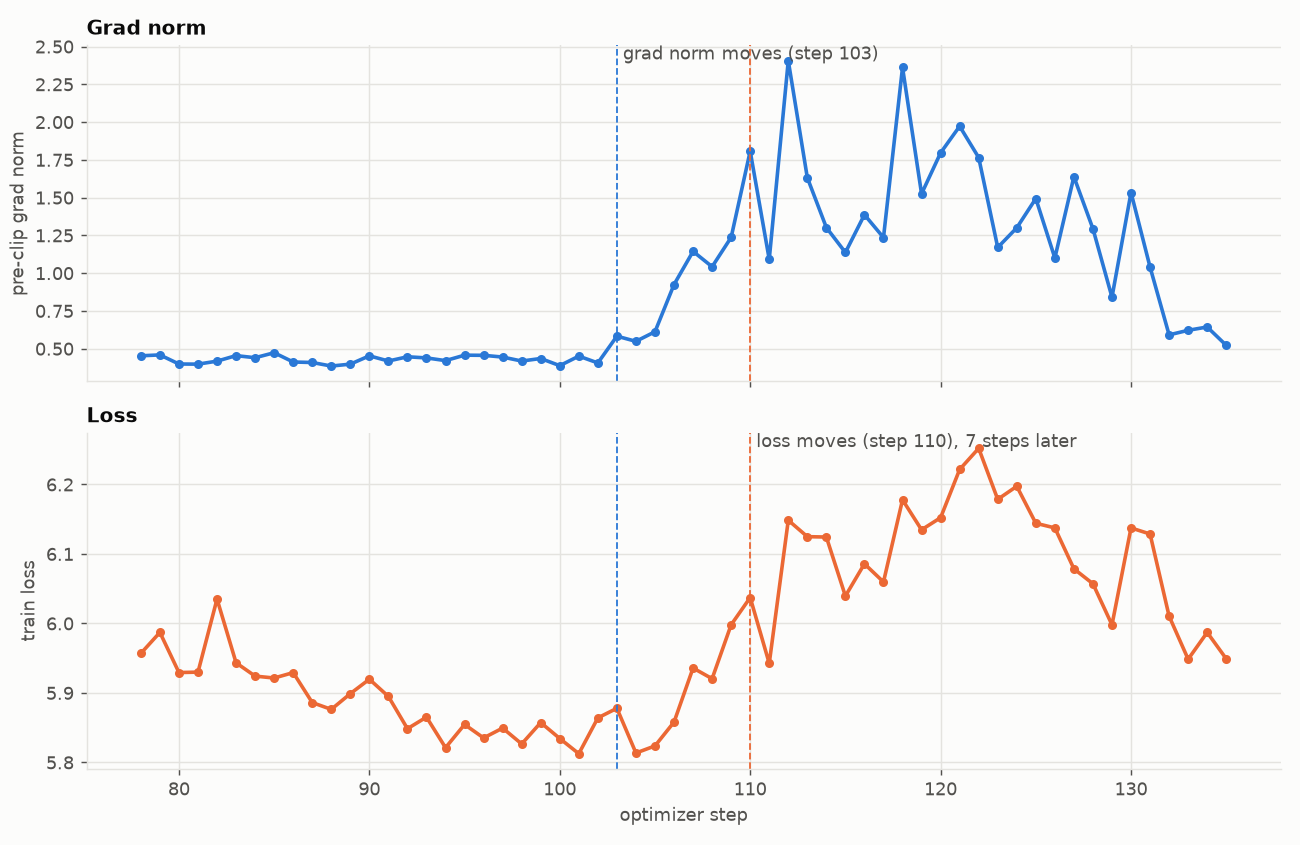

In [12]:
!{PY} train.py --data data/fwe --out runs/spike --max-steps 150 --lr-spike 100:10:5 --eval-every 0 --sample-tokens 0 --print-every 25 --compile --fused-adam
!{PY} find_lead.py runs/spike --skip 60
!{PY} train.py --data data/fwe --out runs/ramp --max-steps 200 --lr-spike 100:20:60 --lr-ramp --eval-every 0 --sample-tokens 0 --print-every 25 --compile --fused-adam
!{PY} find_lead.py runs/ramp --skip 60
if LEAD_RUN is None:
    LEAD_RUN = "runs/ramp"
print("lead plot uses", LEAD_RUN)
!{PY} plot.py --lead {LEAD_RUN} --out plots
display(Image("plots/lead.png"))

## 11. The honest MFU report

This cell reads `runs/main/metrics.jsonl` and summarizes the speed of the whole run, skipping
the first 20 steps (warm-up). It prints the median tokens per second, the median MFU against the
estimated peak, the same against the measured matmul ceiling, and the slowest and fastest steps,
so a slow patch would show up. Guide Part 15 discusses what is costing us the distance between
here and 40%.

In [13]:
recs = [json.loads(l) for l in open("runs/main/metrics.jsonl")]
tr = [r for r in recs if r["type"] == "train"][20:]
cfg = json.load(open("runs/main/config.json"))
tps = np.array([r["tok_per_s"] for r in tr]); mfu = np.array([r["mfu"] for r in tr]); cf = np.array([r["ceiling_frac"] for r in tr])
print(f"N = {cfg['n_params']:,} params, 6N = {6 * cfg['n_params'] / 1e6:.1f} MFLOPs per token")
print(f"peak: {cfg['peak_source']}")
print(f"measured matmul ceiling: {cfg['matmul_ceiling'] / 1e12:.2f} TFLOPS")
print(f"tokens/s: median {np.median(tps):,.0f}, 5th percentile {np.percentile(tps, 5):,.0f}, 95th {np.percentile(tps, 95):,.0f}")
print(f"useful TFLOPS: {6 * cfg['n_params'] * np.median(tps) / 1e12:.2f}")
print(f"MFU vs estimated peak: median {100 * np.median(mfu):.1f}%")
print(f"fraction of measured matmul ceiling: median {100 * np.median(cf):.1f}%")
evals = [r for r in recs if r["type"] == "eval"]
print(f"held-out loss: {evals[0]['loss']:.3f} at step 0 -> {evals[-1]['loss']:.3f} at step {evals[-1]['step']}")
print("\nsample:\n" + open("runs/main/sample.txt").read())

N = 12,297,984 params, 6N = 73.8 MFLOPs per token
peak: Apple M4, 8 GPU cores x 128 ALUs x 2 FLOPs x 1.6 GHz = 3.28 TFLOPS (estimate, same for every dtype)
measured matmul ceiling: 1.53 TFLOPS
tokens/s: median 15,564, 5th percentile 14,108, 95th 18,549
useful TFLOPS: 1.15
MFU vs estimated peak: median 35.0%
fraction of measured matmul ceiling: median 75.2%
held-out loss: 8.396 at step 0 -> 3.925 at step 1519

sample:
The most important thing about learning is a few kind of information related to your students's development and caregivers is an example of your research.
Last month, the project, and the Self-Based Active Climate change helps your child with learning.
Discussion is easy to follow to this list.
The project provides a strong study that is to provide the importance of learning to readiness and the work of teaching.
This project provides the development of learning how to understand more awareness and how to learn from the research project.
What to learn what to teach is lear

## Done

Everything the guide quotes comes from the outputs above:

- `runs/shapes/shapes.txt`: every tensor in one step
- `runs/gradcheck.json`: the hand-checked gradients
- `runs/accum/`: correct against broken accumulation
- `runs/ladder.json`: the MFU ladder
- `runs/main/metrics.jsonl`: the four traces, one line per step
- `runs/spike/`, `runs/ramp/`: the provoked grad-norm events
- `plots/`: the figures

To try something, change one flag and rerun one cell. Guide Part 18 has suggestions.